##### 2. Asequibilidad
**Una vivienda de 90 m² cuesta 172.226 € en España. ¿Es cara? Depende de lo que gane quien la compra.**

El notebook `01` respondió cuánto cuesta. Este responde la pregunta que de verdad
se hace la gente: **¿cuánto de mi sueldo se lleva?** Y, sobre todo, **¿está
mejorando o empeorando?**

**Tres palabras que van a salir todo el rato**

- **Mediana**: el valor que queda justo en el medio al ordenar. La mitad de las
  provincias están por debajo y la mitad por encima. Se usa en vez de la media
  porque una provincia carísima no la arrastra.
- **Percentil 25 / 75**: el valor que deja por debajo al 25 % / 75 % de las
  provincias. Entre los dos está la mitad central del país.
- **Nominal**: euros de cada año, sin corregir por la inflación. Aquí es a
  propósito: el IPC afectaría igual al precio y a la renta.

**Lo que hay que saber antes de mirar**

- El precio es **valor tasado**, no precio de compraventa.
- La renta es **neta por hogar** (ADRH, INE), no por persona.
- La serie empieza en **2015** porque antes no hay renta provincial, y acaba en
  **2024** porque es el último año publicado. **2025 no se puede calcular**: hay
  precio, pero no renta.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El import de src/ funciona tanto si Jupyter se lanza desde la raíz del
# proyecto como desde notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (  # noqa: E402
    FIGURES_DIR,
    INCOME_END_YEAR,
    INCOME_START_YEAR,
    NATIONAL_CODE,
    PROCESSED_DIR,
    PROVINCES,
)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sin dtype, "04" se convierte en 4 y "00" en 0: el cruce por provincia deja
# de casar. Se lee siempre con el código como texto.
panel = pd.read_csv(
    PROCESSED_DIR / "panel_provincia_anual.csv",
    dtype={"province_code": str},
)

# Vivienda total: el mismo agregado que en 01.
total = panel[panel["kind"] == "total"]


##### Bloque 1 · ¿Cuántos años de sueldo cuesta una casa?

**La idea, con algo que no sea una casa.** Un móvil de 6.000 € con un sueldo de
2.000 € al mes cuesta **3 meses de sueldo**. No hace falta saber economía: se
divide el precio entre lo que ganas al mes. Con una vivienda es igual, solo que
el sueldo se mide en años y el precio es el de 90 m²:

`años = (€/m² × 90) ÷ renta neta anual del hogar`

Y la conclusión se lee igual que con el móvil: **cuantos menos años, mejor**.
Cuatro casos reales, con las mismas cuentas:


In [2]:
indexed = total.set_index(["province_code", "year"])

casos = [("13", 2015), ("13", 2024), ("28", 2015), ("28", 2024), (NATIONAL_CODE, 2024)]
rows = []
for code, year in casos:
    row = indexed.loc[(code, year)]
    rows.append({
        "caso": f"{'España' if code == NATIONAL_CODE else PROVINCES[code]} {year}",
        "€/m²": round(float(row["price_nominal_eur_m2"])),
        "piso 90 m²": int(round(row["price_nominal_eur_m2"] * 90)),
        "renta del hogar": int(round(row["net_income_household_eur"])),
        "años": round(float(row["years_90m2"]), 2),
    })

ejemplo = pd.DataFrame(rows).set_index("caso")
display(ejemplo)


,€/m²,piso 90 m²,renta del hogar,años
caso,,,,
Ciudad Real 2015,784,70549,23119,3.05
Ciudad Real 2024,722,64951,33136,1.96
Madrid 2015,2075,186744,37225,5.02
Madrid 2024,3240,291596,51928,5.62
España 2024,1914,172226,40605,4.24


**Leído en voz alta:**

- **Ciudad Real, 2015 → 2024.** El piso de 90 m² pasa de 70.549 € a 64.951 €
  (baja), y la renta del hogar de 23.119 € a 33.136 € (sube mucho más). La
  división pasa de 3,05 a 1,96 años: **mejora**.
- **Madrid, 2015 → 2024.** El piso pasa de 186.744 € a 291.596 € (+56 %) y la
  renta de 37.225 € a 51.928 € (+39 %). El precio corre más que el sueldo: de
  5,02 a 5,62 años. **Empeora.**

Ese es todo el mecanismo: **una división**. Y de ahí sale la primera consecuencia
incómoda: que la vivienda sea más o menos asequible no depende solo de cuánto
sube el precio, sino de si el sueldo sube más o menos que él.


##### La misma cuenta, provincia a provincia

La tabla anterior tiene cinco filas. La gráfica tiene **49 provincias × 10 años**.
Para que quepa en una línea, cada año se resume en tres números:

- **Línea azul: la mediana.** Se ordenan las 49 provincias de menor a mayor
  esfuerzo y se toma la que queda en medio. No es la media: una provincia
  carísima no la arrastra. Si baja, la provincia típica necesita menos años.
- **Banda azul: el 50 % central.** Entre el percentil 25 (deja 12 provincias por
  debajo) y el 75. Si la banda se abre, las provincias se separan; si se
  estrecha, se parecen.
- **Línea roja: España.** No es una provincia ni la media de las 49: es la cifra
  que publica el INE para el conjunto del país, ponderada por el peso de cada
  mercado. Solo existe 2021–2024.

Dos avisos para no leerla al revés:

- **Más abajo es mejor.** El eje son años que hay que pagar, no euros.
- El eje empieza en 2,2, no en cero. En una línea se puede hacer porque marca
  una posición; en una barra, nunca.

**¿Y por qué 49 y no 52?** Porque tres provincias no tienen renta en 2015:
Álava, Gipuzkoa y Navarra. Si se añadieran solo en los años en que existen, la
mediana cambiaría de provincias a mitad de serie y la subida o bajada podría ser
un efecto de quién entra, no del tiempo. Se fija el grupo y se compara siempre lo
mismo.


In [3]:
# El "00" es España, no una provincia: fuera de la serie provincial.
provincial = total[total["province_code"] != NATIONAL_CODE]

# Se fija el panel a las provincias con los diez años completos para que la
# mediana no cambie de composición a mitad de serie.
wide = provincial.pivot(index="province_code", columns="year", values="years_90m2")
years = range(INCOME_START_YEAR, INCOME_END_YEAR + 1)
balanced = wide.loc[:, years].dropna()

serie = pd.DataFrame({
    "p25": balanced.quantile(0.25),
    "mediana": balanced.median(),
    "p75": balanced.quantile(0.75),
})

# España solo existe de 2021 en adelante: el ADRH no publica Total Nacional
# entre 2015 y 2020. Es un hueco del dato, no un cero.
nacional = (
    total.loc[total["province_code"] == NATIONAL_CODE]
    .set_index("year")["years_90m2"]
    .dropna()
)

print(f"Provincias en la serie: {len(balanced)}")
print("Fuera por falta de renta en 2015: "
      + ", ".join(PROVINCES[c] for c in wide.index.difference(balanced.index)))
print(f"España: {int(nacional.index.min())}-{int(nacional.index.max())}")


Provincias en la serie: 49
Fuera por falta de renta en 2015: Araba/Álava, Gipuzkoa, Navarra
España: 2021-2024


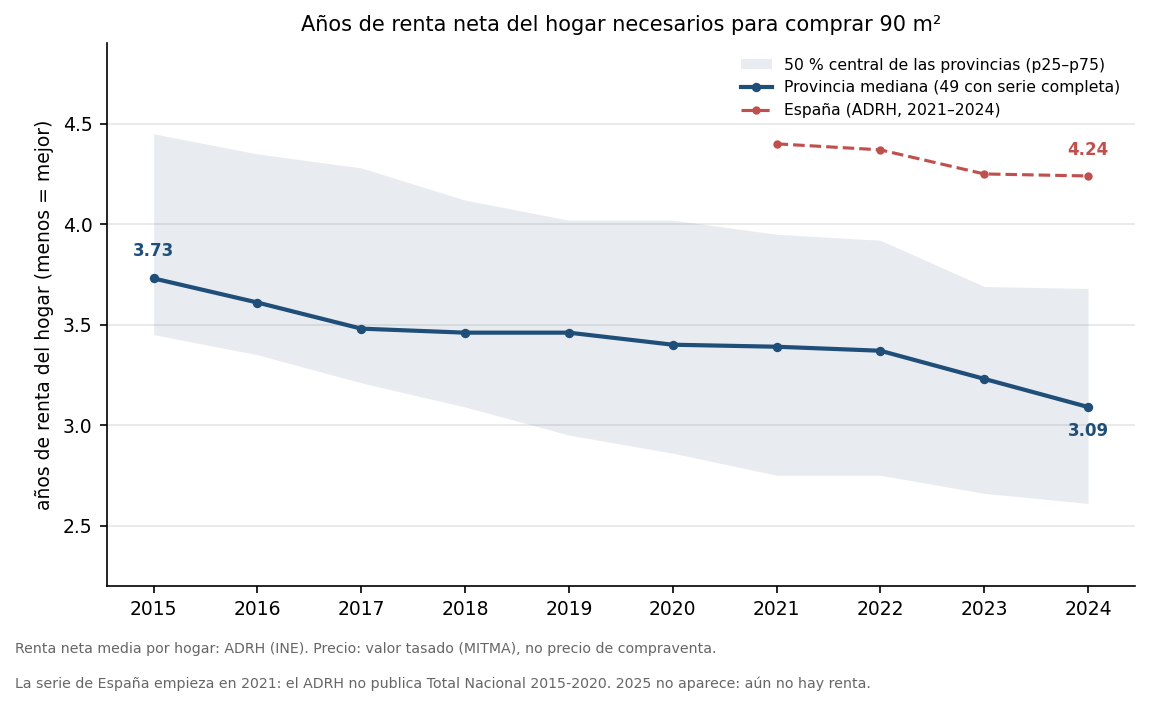

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 4.3))

ax.fill_between(
    serie.index, serie["p25"], serie["p75"],
    color="#1f4e79", alpha=0.10, linewidth=0,
    label="50 % central de las provincias (p25–p75)",
)
ax.plot(
    serie.index, serie["mediana"],
    color="#1f4e79", linewidth=2, marker="o", markersize=3.5,
    label=f"Provincia mediana ({len(balanced)} con serie completa)",
)
ax.plot(
    nacional.index, nacional,
    color="#c0504d", linewidth=1.5, linestyle="--", marker="o", markersize=3,
    label="España (ADRH, 2021–2024)",
)

ax.set_title("Años de renta neta del hogar necesarios para comprar 90 m²")
ax.set_ylabel("años de renta del hogar (menos = mejor)")
ax.set_xticks(list(years))
ax.set_ylim(2.2, 4.9)
ax.grid(axis="y", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=7.5)

for year, dy in ((2015, 11), (2024, -14)):
    ax.annotate(
        f"{serie.loc[year, 'mediana']:.2f}",
        (year, serie.loc[year, "mediana"]),
        textcoords="offset points", xytext=(0, dy),
        ha="center", fontsize=8, color="#1f4e79", fontweight="bold",
    )

ax.annotate(
    f"{nacional.iloc[-1]:.2f}",
    (nacional.index[-1], nacional.iloc[-1]),
    textcoords="offset points", xytext=(0, 10),
    ha="center", fontsize=8, color="#c0504d", fontweight="bold",
)

fig.text(
    0.0, -0.02,
    "Renta neta media por hogar: ADRH (INE). Precio: valor tasado (MITMA), "
    "no precio de compraventa.",
    fontsize=6.8, color="0.4",
)
fig.text(
    0.0, -0.075,
    "La serie de España empieza en 2021: el ADRH no publica Total Nacional "
    "2015-2020. 2025 no aparece: aún no hay renta.",
    fontsize=6.8, color="0.4",
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_evolucion.png", bbox_inches="tight")
plt.show()


In [5]:
resumen = serie.loc[[2015, 2021, 2024]].round(2)
resumen.index.name = "año"
display(resumen)

mediana_2015 = serie.loc[2015, "mediana"]
mediana_2024 = serie.loc[2024, "mediana"]

print(f"Mediana 2015: {mediana_2015:.2f} -> 2024: {mediana_2024:.2f} "
      f"({mediana_2024 / mediana_2015 - 1:+.1%})")
print(f"p25: {serie.loc[2015, 'p25']:.2f} -> {serie.loc[2024, 'p25']:.2f} "
      f"({serie.loc[2024, 'p25'] / serie.loc[2015, 'p25'] - 1:+.1%})")
print(f"p75: {serie.loc[2015, 'p75']:.2f} -> {serie.loc[2024, 'p75']:.2f} "
      f"({serie.loc[2024, 'p75'] / serie.loc[2015, 'p75'] - 1:+.1%})")

# La misma ventana para comparar con España, que solo tiene 2021-2024.
print(f"Mediana provincial 2021-2024: {serie.loc[2021, 'mediana']:.2f} -> "
      f"{mediana_2024:.2f} ({mediana_2024 / serie.loc[2021, 'mediana'] - 1:+.1%})")
print(f"España 2021-2024: {nacional.loc[2021]:.2f} -> {nacional.loc[2024]:.2f} "
      f"({nacional.loc[2024] / nacional.loc[2021] - 1:+.1%})")

# La mediana de 2024 con las 52 provincias, para no esconder la diferencia.
todas_2024 = provincial.loc[
    (provincial["year"] == 2024) & provincial["years_90m2"].notna(), "years_90m2"
]
print(f"Mediana 2024 con las {len(todas_2024)} provincias: {todas_2024.median():.2f}")

for year in (2015, 2024):
    values = balanced[year]
    print(f"{year}: p90/p10 {values.quantile(.9) / values.quantile(.1):.2f}x | "
          f"max/min {values.max() / values.min():.2f}x")


,p25,mediana,p75
año,,,
2015,3.45,3.73,4.45
2021,2.75,3.39,3.95
2024,2.61,3.09,3.68


Mediana 2015: 3.73 -> 2024: 3.09 (-17.2%)
p25: 3.45 -> 2.61 (-24.3%)
p75: 4.45 -> 3.68 (-17.3%)
Mediana provincial 2021-2024: 3.39 -> 3.09 (-8.8%)
España 2021-2024: 4.40 -> 4.24 (-3.6%)
Mediana 2024 con las 52 provincias: 3.24
2015: p90/p10 1.56x | max/min 2.34x
2024: p90/p10 1.92x | max/min 3.10x


##### Lo que dicen los datos

**¿Qué muestra la línea azul, en una frase?**
Los años de renta que necesita la provincia que queda en medio de las 49. En 2015
eran **3,73** (casi cuatro años de sueldo entero); en 2024, **3,09** (tres años y
un mes).

**¿3,09 años es mucho o poco?**
Mucho. Significa dedicar **tres años enteros de todo lo que ingresa el hogar** a
pagar la casa, sin comer, sin luz y sin colegio. Si se destinara a la vivienda el
30 % de la renta —la proporción que suele considerarse razonable—, harían falta
unos **10,3 años** para cubrir el precio, y eso sin contar intereses. En Madrid
(5,62) serían **18,7 años**; en Ciudad Real (1,96), 6,5.

**¿Ha mejorado o empeorado desde 2015?**
Mejorado: de **3,73 a 3,09 años (−17,2 %)**. Es la diferencia entre deber casi
cuatro años de sueldo y deber tres.

**Pero si los precios han subido, ¿cómo puede mejorar?**
Porque la renta subió mucho más. Entre 2015 y 2024, en esas mismas 49 provincias,
el precio nominal mediano subió un **13,0 %** y la renta neta mediana del hogar,
un **41,1 %**. La mejora no la hizo el ladrillo: la hizo el sueldo.

Y hay una trampa de lectura: **2015 es el peor año de la serie** (3,73). Si se
compara 2024 con 2021, la mejora es del 8,8 %, no del 17,2 %. El punto de partida
elegido cambia el titular, y conviene decirlo.

**¿Mejora en todas partes?**
No. **45 de las 49 provincias mejoran y 4 empeoran**: Madrid (+12,0 %), Baleares
(+5,5 %), Málaga (+3,8 %) y Barcelona (+1,8 %). Son justo las cuatro donde el
precio creció más que la renta. Eso es el bloque 3.

**¿Por qué la línea de España va por encima y baja menos?**
En 2021, España marca 4,40 y la provincia mediana 3,39. No es un error: la cifra
nacional está **ponderada por el mercado**, así que pesa mucho Madrid, Barcelona
y Baleares, que son caras. Es la misma historia que en el `01` con 2.128 frente a
1.421. Por eso, entre 2021 y 2024, la mediana provincial cae un **8,8 %** y
España solo un **3,6 %**: las provincias que empeoran son las que más pesan en el
total nacional.

**¿Y la banda azul?**
Es la prueba de que el país se separa. El percentil 25 cae un **24,3 %** y el 75
solo un **17,3 %**: las provincias baratas mejoran más rápido que las caras. El
máximo dividido entre el mínimo pasa de **2,3 a 3,1 veces**, y el p90/p10, de 1,6
a 1,9. La media mejora y la brecha se abre.

**¿Y 2025?**
El precio subió un **11,2 % nominal** y no hay renta publicada. Si la renta
creciera al ritmo del periodo (3,9 % anual), el esfuerzo subiría cerca de un 7 %
en un solo año. Es una estimación, no un dato, pero sirve para no leer esta
gráfica como si siguiera viva: **la serie termina justo cuando venía mejorando**.

**¿Qué no dice este bloque?**

- No dice el precio de compraventa: es **valor tasado**.
- No dice si puedes pagar una hipoteca: no hay tipos, entrada ni plazo.
- No dice nada de **2007–2014**: no hay renta provincial.
- El nivel exacto depende de las 49: con las 52 provincias, la mediana de 2024
  es **3,24**, no 3,09. La serie usa 49 para que el cambio sea comparable.
- La «provincia mediana» no es donde vive la persona mediana: Madrid y Barcelona
  concentran mucha más población que su peso en el conteo de provincias.

**Entonces, ¿cuál es el problema?**
Que la vivienda en España no es un problema único, sino dos. En la mayoría del
país el acceso **mejoró** entre 2015 y 2024 porque los sueldos subieron más que
los precios. En Madrid, Baleares, Málaga y Barcelona ocurrió lo contrario, y son
las zonas donde más gente quiere vivir y donde más pesa el mercado. El resultado
no es un país más caro: es un país **más desigual**, con una brecha que pasó de
2,3 a 3,1 veces. Y en 2025 el precio vuelve a subir sin que sepamos si la renta
lo acompaña.

En el bloque 2 ponemos esto en el mapa: **¿dónde duele?**
